# 2. What is in a structure

Reading a file into a `TCRFrame` annotates it:

- each chain gets a role and a standard ID (A MHC, B MHC beta, C peptide, D TCR alpha,
  E TCR beta, F B2M);
- the TCR V domains get IMGT numbering from ANARCI;
- the MHC groove domains get IMGT G-DOMAIN numbering.

From these come the regions (CDRs, MHC helices, peptide core, ...), which you can select
and display by name. The example is 1AO7: the A6 TCR on HLA-A*02:01 with the Tax peptide.
Every attribute is listed in [docs/tcrframe.md](../docs/tcrframe.md), starting with a
one-screen summary.

In [1]:
import pandas as pd
import tcrkit

import tcrstruct as tcs
from tcrstruct import TCRFrame

pd.options.display.precision = 3

In [2]:
s = TCRFrame.read(tcs.example('1AO7', 'rcsb.pdb'), name='1AO7')
print(s.report())

TCRFrame '1AO7', MHC class I, chains A, C, D, E, F
  A  MHC heavy chain A0201        274 aa   (chain A in the file)
  C  peptide                        9 aa   (chain C in the file)
  D  TCR alpha       TRAV12-2*01  115 aa   (chain D in the file)
  E  TCR beta        TRBV6-5*01   209 aa   (chain E in the file)
  F  B2M             B2M_human    100 aa   (chain F in the file)
  peptide LLFGYPVYV
  CDRs    CDRA1=DRGSQS  CDRA2=IYSNGD  CDRA3=AVTTDSWGKLQ  CDRB1=MNHEY  CDRB2=SVGAGI  CDRB3=ASRPGLAGGRPEQY


The structure, with the sequences shown and the CDR3s and MHC helices marked. Hover a
residue in the sequence or in 3D to find it in the other; click a region in the legend
to switch it off.

In [3]:
s.view(regions=['cdr3', 'helices'], sequence=True, tcr_up=True)

## Chains

One row per chain: its role, gene and closest allele, and the identity to that allele.
For the MHC and B2M that is the closest database allele; for the TCR chains the V gene
and allele (with the J allele after it), from ANARCI. `original_chain` is the chain's ID
in the file.

In [4]:
s.chain_table.drop(columns='sequence')

,role,gene,allele,identity,j_gene,j_identity,original_chain,length
chain,,,,,,,,
A,MHC heavy chain,A,A0201,1.000,-,NaN,A,274
C,peptide,-,-,NaN,-,NaN,C,9
D,TCR alpha,TRAV12-2,TRAV12-2*01,0.957,TRAJ24*02,1.0,D,115
E,TCR beta,TRBV6-5,TRBV6-5*01,0.958,TRBJ2-7*01,1.0,E,209
F,B2M,B2M,B2M_human,0.980,-,NaN,F,100


## Sequences

`s.sequence(name)` gives the sequence of a chain or of any region in one chain:

In [5]:
{name: s.sequence(name) for name in ['C', 'peptide_core', 'CDRA3', 'CDRB3']}

{'C': 'LLFGYPVYV',
 'peptide_core': 'LLFGYPVYV',
 'CDRA3': 'AVTTDSWGKLQ',
 'CDRB3': 'ASRPGLAGGRPEQY'}

## TCR: CDRs and IMGT numbering

The CDRs are IMGT ranges: CDR1 27-38, CDR2 56-65, CDR3 105-117. `s.residues` has one
row per residue, with its IMGT label (`imgt`) and the region it is in. The file's own
numbering stays in `residue_number`.

In [6]:
s.cdrs

{'CDRA1': 'DRGSQS',
 'CDRA2': 'IYSNGD',
 'CDRA3': 'AVTTDSWGKLQ',
 'CDRB1': 'MNHEY',
 'CDRB2': 'SVGAGI',
 'CDRB3': 'ASRPGLAGGRPEQY'}

In [7]:
s.residues.query("region == 'CDRB3'")[['chain', 'residue_number', 'imgt', 'aa', 'region']]

,chain,residue_number,imgt,aa,region
487,E,105,105,A,CDRB3
488,E,106,106,S,CDRB3
489,E,107,107,R,CDRB3
490,E,108,108,P,CDRB3
491,E,109,109,G,CDRB3
492,E,110,110,L,CDRB3
493,E,111,111,A,CDRB3
494,E,112,112A,G,CDRB3
495,E,112,112,G,CDRB3
496,E,113,113,R,CDRB3


## MHC: G domains, strands and helices

The MHC chains are numbered on IMGT's G-DOMAIN scheme:

- the G domains: class I has G-ALPHA1 and G-ALPHA2; class II has G-ALPHA and G-BETA;
- IMGT's strands A-D (1-49) and helix region (50-92);
- the groove-helix residues used for the docking angles;
- the topology (extracellular, transmembrane, ...).

`tcs.mhc.mhc_match` summarizes one chain:

In [8]:
tcs.mhc.mhc_match(s.sequences['A'])[['gene', 'allele', 'allele_identity', 'mhc_class',
                                     'domains', 'domain_spans', 'helix']]

gene                                A
allele                          A0201
allele_identity                   1.0
mhc_class                           I
domains            G-ALPHA1, G-ALPHA2
domain_spans             1-90, 91-182
helix                  50-86, 140-176
Name: 0, dtype: object

The crystal structure has only the extracellular part of the heavy chain. The full
HLA-A*02:01 chain (signal peptide to cytoplasmic tail) from tcrkit, annotated residue by
residue:

In [9]:
a2 = tcrkit.mhc_sequence('HLA-A*02:01', region='full', squeeze=True)['sequence']
tcrkit.print_residues(tcrkit.annotate_mhc({'HLA-A2': a2}, per_residue=True), width=70,
                      color=True)

HLA-A2  365 residues
          1         11        21        31        41        51        61
sequence  MAVMAPRTLVLLLSGALALTQTWAGSHSMRYFFTSVSRPGRGEPRFIAVGYVDDTQFVRFDSDAASQRME
topology  SSSSSSSSSSSSSSSSSSSSSSSSOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOO
domain                            1111111111111111111111111111111111111111111111
region                            AAAAAAAAAAAAAA...BBBBBBBBBBB..CCCCCCCC...DDDDD
helix

          71        81        91        101       111       121       131
sequence  PRAPWIEQEGPEYWDGETRKVKAHSQTHRVDLGTLRGYYNQSEAGSHTVQRMYGCDVGSDWRFLRGYHQY
topology  OOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOOO
domain    1111111111111111111111111111111111111111111122222222222222222222222222
region    DDDHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHAAAAAAAAAAAAAA...BBBBBBBBB
helix        HHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHHH

          141       151       161       171       181       191       201
sequence  AYDGKDYIALKEDLRSWTAADMAAQTTKHKWEAAHVAEQLR

On a structure, `tcs.mhc.mhc_numbering` gives the same per residue, next to the file's
numbering:

In [10]:
tcs.mhc.mhc_numbering(s).query("residue_number in [50, 62, 63, 66, 150, 155]")

,chain,observed_index,residue_number,insertion_code,gene,allele,domain,imgt,region,helix,aa,topology
49,A,50,50,,A,A0201,G-ALPHA1,50,helix,True,P,extracellular
61,A,62,62,,A,A0201,G-ALPHA1,62,helix,True,G,extracellular
62,A,63,63,,A,A0201,G-ALPHA1,63,helix,True,E,extracellular
65,A,66,66,,A,A0201,G-ALPHA1,66,helix,True,K,extracellular
149,A,150,150,,A,A0201,G-ALPHA2,61A,helix,True,A,extracellular
154,A,155,155,,A,A0201,G-ALPHA2,66,helix,True,Q,extracellular


## Peptide core

On class I the peptide core is the whole peptide. On class II it is the 9 residues that
sit in the groove. tcrstruct finds them from the structure: the 9 consecutive residues
closest to the MHC.

In [11]:
class_ii = TCRFrame.read(tcs.example('3QIB', 'rcsb.pdb'), name='3QIB')
class_ii.peptide, class_ii.sequence('peptide_core')

('LIAYLKQATKG', 'IAYLKQATK')

## Regions

These are all the regions you can mark or select by name. `defined_by` says how each is
found: by **IMGT positions** (the same in every structure), by **distance** (from the
coordinates), or as a **whole chain**.

In [12]:
tcs.list_regions()

,chains,defined_by,imgt,description
region,,,,
peptide,C,whole chain,-,the whole peptide (chain C)
peptide_core,C,whole chain (class I); distance to the MHC (cl...,-,the whole peptide (class I) or its 9-mer close...
peptide_centric,any,distance: within 10 A of the peptide core,-,residues of any chain within 10 A of the pepti...
CDRA1,D,IMGT positions,27-38,IMGT CDR1 of TCR alpha
CDRA2,D,IMGT positions,56-65,IMGT CDR2 of TCR alpha
CDRA3,D,IMGT positions,105-117,IMGT CDR3 of TCR alpha
CDRB1,E,IMGT positions,27-38,IMGT CDR1 of TCR beta
CDRB2,E,IMGT positions,56-65,IMGT CDR2 of TCR beta
CDRB3,E,IMGT positions,105-117,IMGT CDR3 of TCR beta


Groups name several regions at once (`'cdr3'`, `'cdrs'`, `'tcr'`, ...):

In [13]:
tcs.list_region_groups()

,regions
group,
default,"peptide_core, CDRA1, CDRA2, CDRA3, CDRB1, CDRB..."
all,"peptide, peptide_core, peptide_centric, CDRA1,..."
cdrs,"CDRA1, CDRA2, CDRA3, CDRB1, CDRB2, CDRB3"
cdr1,"CDRA1, CDRB1"
cdr2,"CDRA2, CDRB2"
cdr3,"CDRA3, CDRB3"
cdras,"CDRA1, CDRA2, CDRA3"
cdrbs,"CDRB1, CDRB2, CDRB3"
tcr,"TCRa, TCRb"


Any of them can be displayed. For example, `peptide_centric` is every residue within
10 Å of the peptide core, the region the benchmark superposes models on:

In [14]:
s.view(regions=['peptide_centric', 'peptide_core'], tcr_up=True, sequence=True)

## Selecting regions

`s.select(regions=...)` returns a new TCRFrame with only those atoms. It still knows its
regions, so you can read its sequences, display it, or write it to a file:

In [15]:
part = s.select(regions=['cdr3', 'peptide_core'])
part.sequences

{'C': 'LLFGYPVYV', 'D': 'AVTTDSWGKLQ', 'E': 'ASRPGLAGGRPEQY'}

In [16]:
part.view()

## Several structures on top of each other

Two more class I complexes from the test data, with other TCRs and peptides, each fitted
onto 1AO7 by its MHC heavy chain. Only the CDR3s and the peptide are shown, to compare
where the loops sit over the groove.

In [17]:
others = {p: TCRFrame.read(tcs.example(p, 'rcsb.pdb'), name=p).superpose(s, chains=['A'])
          for p in ['6ZKW', '7N2N']}          # fit on chain A; the whole structure moves
pd.DataFrame({p: o.summary()[['mhc', 'peptide', 'TRAV', 'TRBV']] for p, o in others.items()})

,6ZKW,7N2N
mhc,E0103,B2705
peptide,RLPAKAPLL,TRLALIAPK
TRAV,TRAV21*01,TRAV21*01
TRBV,TRBV6-5*01,TRBV9*01


In [18]:
keep = ['cdr3', 'peptide']
tcs.view_comparison({p: o.select(regions=keep) for p, o in others.items()},
                    s.select(regions=keep), superpose=False, values=None, regions=keep,
                    tcr_up=True)

## Which CDR residues touch which peptide residues

`s.contact_map()` lists every CDR residue within 5 Å of the peptide (closest heavy
atoms). A CDR residue is labelled by its region, amino acid and IMGT position
(`CDRB3 L110`). A peptide residue is labelled by its amino acid and its position in the
peptide core, so `L1 L2 F3 G4 Y5 P6 V7 Y8 V9` is the Tax peptide LLFGYPVYV. For a class
II peptide, 1 is the core's first residue (P1), and the flanks are `-1, -2, ...` and
`10, 11, ...`.

In [19]:
s.contact_map().head(10)

,row,column,distance,row_chain,row_region,row_imgt,column_chain,column_region,column_imgt
0,CDRA1 G29,L1,4.328,D,CDRA1,29,C,peptide_core,-
1,CDRA1 Q37,L2,3.131,D,CDRA1,37,C,peptide_core,-
2,CDRA1 Q37,G4,3.444,D,CDRA1,37,C,peptide_core,-
3,CDRA1 Q37,L1,3.664,D,CDRA1,37,C,peptide_core,-
4,CDRA1 Q37,F3,4.256,D,CDRA1,37,C,peptide_core,-
5,CDRA1 Q37,Y5,4.927,D,CDRA1,37,C,peptide_core,-
6,CDRA1 S38,Y5,2.542,D,CDRA1,38,C,peptide_core,-
7,CDRA3 T107,Y5,3.394,D,CDRA3,107,C,peptide_core,-
8,CDRA3 T108,G4,4.332,D,CDRA3,108,C,peptide_core,-
9,CDRA3 T108,Y5,4.442,D,CDRA3,108,C,peptide_core,-


`grid=True` gives the same as a grid, and `tcs.plot_contact_map` draws it. Each row is a
CDR residue and each column a peptide position; the darker the cell, the closer the two
residues. An empty cell means no contact within 5 Å. Here CDR1α and CDR3α sit over the
peptide's N-terminal half (L1-Y5) and CDR3β over its C-terminal half (Y5-Y8); Y5, in the
middle, touches both CDR3s. Other regions work too, e.g.
`s.contact_map(rows='cdrs', columns='helices')`.

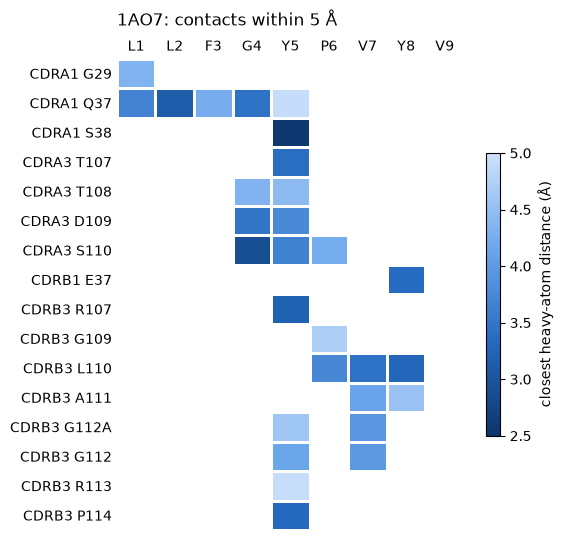

In [20]:
tcs.plot_contact_map(s);

Checking a structure (complete chains, contacts, several copies of the complex in one file,
chain breaks) and splitting it into parts are in [05_verification](05_verification.ipynb).